# 04 — Cleaning dan Data Preparation
## Prediksi Harga Mobil Bekas di Indonesia
Kelompok Bersifat Opsional — lanjutan notebook 01–03, memenuhi rubrik 10–14.

Target adalah `price (Rp)` (regresi harga penawaran). Jalankan cell dari atas ke bawah. Letakkan `used_car.csv` di folder yang sama atau `data/` pada root proyek. Library yang diperlukan adalah pandas, numpy, matplotlib, scikit-learn, dan IPython. Jika diperlukan, install dengan `%pip install pandas numpy matplotlib scikit-learn ipython`.

Urutan kerja adalah cleaning berbasis aturan, split, preprocessing, lalu seleksi fitur. Split dilakukan sebelum menghitung median, scaling, dan seleksi agar informasi test tidak masuk ke pelatihan.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge

TARGET = "price (Rp)"
SEED = 42
paths = [Path("used_car.csv"), Path("data/used_car.csv"),
         Path("../data/used_car.csv"), Path("../used_car.csv")]
DATA_PATH = next((p for p in paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Letakkan used_car.csv di folder notebook atau ../data/.")
raw = pd.read_csv(DATA_PATH)
print("Dimensi awal:", raw.shape)
display(raw.head())

,car name,brand,year,mileage (km),location,transmission,plate type,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control,price (Rp),instalment (Rp|Monthly)
0,AYLA X 1.2,Daihatsu,2018,10.508,Jakarta Utara,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,101000000,2060000
1,AGYA TRD SPORTIVO 1.0,Toyota,2015,112.888,Bogor,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,82000000,1670000
2,X-TRAIL 2.5,Nissan,2015,118.429,Surabaya,Automatic,odd plate,0,0,0,0,0,0,1,0,1,0,0,169000000,3440000
3,YARIS S TRD 1.5,Toyota,2020,15.945,Tangerang Selatan,Automatic,odd plate,0,0,0,0,0,0,0,0,0,0,0,218000000,4440000
4,AGYA G 1.2,Toyota,2019,30.404,Jakarta Barat,Manual,odd plate,0,0,0,0,0,0,0,0,0,0,0,117000000,2380000


Dimensi awal: (609, 20)


## 10. Cleaning
- Rapikan spasi kategori dan samakan kapitalisasi agar kategori yang sama tidak terpisah.
- Lokasi `Unknown` dipertahankan sebagai kategori informasi tidak tersedia. Mengisinya dengan kota terpopuler dapat menambah bias geografis.
- Hapus duplikasi persis dengan asumsi baris identik merupakan pengulangan listing. Dataset ini tidak memiliki duplikasi persis.
- Harga kosong/tidak positif dibuang karena target harus diketahui. Nilai fitur numerik yang tidak valid dijadikan missing, kemudian diimputasi setelah split.
- Median untuk tahun dan mileage tahan terhadap nilai ekstrem. Modus untuk fitur biner menjaga nilai 0/1. Pada data yang diberikan, imputasi numerik merupakan antisipasi karena tidak ditemukan missing.
- Harga mahal dan mileage tinggi dipertahankan selama masih valid secara aturan. Flag IQR saja belum membuktikan kesalahan.

Format mileage belum dikonfirmasi dari sumber. Nilai dibaca seperti CSV tanpa mengubah tanda titik atau mengalikan satuannya. Tahun pemeriksaan ditetapkan 2026 agar hasil dapat direproduksi.

In [ ]:
df = raw.copy()
category_cols = df.select_dtypes(include="object").columns.tolist()
binary_cols = raw.columns[7:18].tolist()
numeric_cols = ["year", "mileage (km)", TARGET, "instalment (Rp|Monthly)"]

for col in category_cols:
    df[col] = df[col].str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
    df[col] = df[col].replace({"": np.nan, "unknown": np.nan, "n/a": np.nan})
    df[col] = df[col].fillna("unknown")

for col in numeric_cols + binary_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

for col in binary_cols:
    df.loc[~df[col].isin([0, 1]), col] = np.nan

df.loc[(df["year"] < 1886) | (df["year"] > 2026)
       | (df["year"] % 1 != 0), "year"] = np.nan
df.loc[df["mileage (km)"] < 0, "mileage (km)"] = np.nan
invalid_target = df[TARGET].isna() | (df[TARGET] <= 0)
print("Baris target tidak valid:", invalid_target.sum())
df = df.loc[~invalid_target].drop_duplicates().copy()
print("Dimensi setelah cleaning:", df.shape)

Baris target tidak valid: 0
Dimensi setelah cleaning: (609, 20)


## 11. Kondisi sebelum dan sesudah cleaning
Tabel pertama mengevaluasi cleaning berbasis aturan. Missing pada fitur, bila ada, baru diisi dari data train pada bagian 12. Jumlah baris yang sama merupakan hasil yang wajar ketika tidak ada baris yang perlu dibuang.

,Sebelum,Sesudah
Jumlah baris,609,609
Jumlah kolom,20,20
Missing aktual,0,0
Duplikasi persis,0,0
Lokasi tidak diketahui,52,52


,Kategori sebelum,Kategori sesudah
0,Jakarta Utara,jakarta utara
1,Bogor,bogor
2,Surabaya,surabaya
3,Tangerang Selatan,tangerang selatan
4,Jakarta Barat,jakarta barat


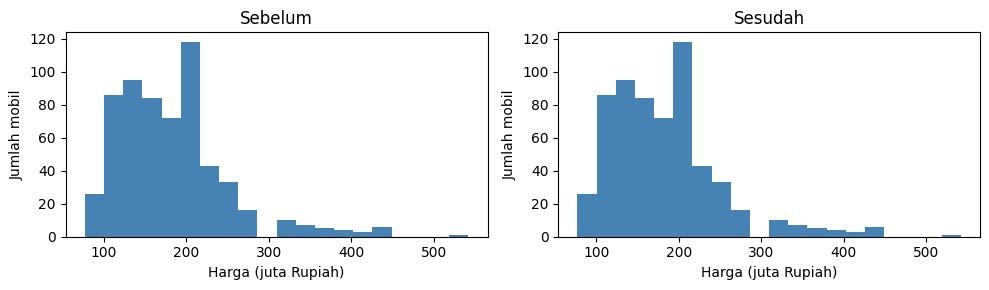

In [ ]:
def quality(data):
    return pd.Series({
        "Jumlah baris": len(data),
        "Jumlah kolom": data.shape[1],
        "Missing aktual": int(data.isna().sum().sum()),
        "Duplikasi persis": int(data.duplicated().sum()),
        "Lokasi tidak diketahui": int(data["location"].str.lower().eq("unknown").sum())
    })

display(pd.DataFrame({"Sebelum": quality(raw), "Sesudah": quality(df)}))
display(pd.DataFrame({"Kategori sebelum": raw["location"].head(),
                      "Kategori sesudah": df["location"].head()}))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, data, title in zip(axes, [raw, df], ["Sebelum", "Sesudah"]):
    ax.hist(data[TARGET] / 1_000_000, bins=20, color="steelblue")
    ax.set(title=title, xlabel="Harga (juta Rupiah)", ylabel="Jumlah mobil")
plt.tight_layout()
plt.show()

## 13. Split train dan test
Gunakan 80% train dan 20% test dengan `random_state=42`. Ini mengasumsikan listing merupakan observasi independen. Identitas kendaraan dan waktu listing tidak tersedia untuk memeriksa kendaraan berulang atau membuat split waktu.

Cicilan dikeluarkan sejak awal karena waktu ketersediaannya belum jelas dan mungkin dihitung dari harga. Target tetap dalam Rupiah. Test disimpan untuk evaluasi model pada tahap berikutnya.

In [ ]:
X = df.drop(columns=[TARGET, "instalment (Rp|Monthly)"])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Train:", X_train.shape, "Test:", X_test.shape)
assert set(X_train.index).isdisjoint(X_test.index)

Train: (487, 18) Test: (122, 18)


## 12. Preprocessing dan ketimpangan data
**Encoding** menggunakan One-Hot Encoding karena merek, model, lokasi, transmisi, dan tipe pelat merupakan kategori tanpa urutan. Kategori yang hanya muncul sekali di train dikelompokkan dengan `min_frequency=2` untuk mengurangi kolom sangat langka. Kategori baru di test ditangani oleh encoder.

**Scaling** menggunakan StandardScaler pada tahun dan mileage karena rentangnya berbeda. Fitur biner sudah bernilai 0/1 sehingga cukup diimputasi modus. Semua parameter dipelajari dari train.

**Ketimpangan** diperiksa melalui jumlah merek dan rentang harga. Target berupa angka kontinu sehingga SMOTE klasifikasi tidak digunakan. Seluruh observasi valid dipertahankan karena oversampling merek sangat langka berisiko mengulang satu listing. Cross-validation digunakan untuk menilai kestabilan seleksi. Jumlah observasi per kelompok tetap ditampilkan agar keterbatasan representasi terlihat. Ini tidak menghilangkan bias sampel terhadap merek atau lokasi tertentu.

In [ ]:
display(X_train["brand"].value_counts().to_frame("Jumlah train"))
price_bins = [0, 150_000_000, 250_000_000, np.inf]
price_labels = ["<150 juta", "150–<250 juta", ">=250 juta"]
display(pd.cut(y_train, bins=price_bins, labels=price_labels, right=False)
        .value_counts(sort=False).to_frame("Jumlah train"))

def make_preprocessor(columns):
    num = [c for c in ["year", "mileage (km)"] if c in columns]
    cat = [c for c in category_cols if c in columns]
    binary = [c for c in binary_cols if c in columns]
    return ColumnTransformer([
        ("numerik", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num),
        ("kategori", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=2,
                                      sparse_output=False))
        ]), cat),
        ("biner", SimpleImputer(strategy="most_frequent"), binary)
    ], verbose_feature_names_out=False)

,Jumlah train
brand,
toyota,138
honda,116
daihatsu,69
mitsubishi,52
suzuki,48
nissan,28
wuling,15
mazda,11
datsun,4


,Jumlah train
price (Rp),
<150 juta,181
150–<250 juta,251
>=250 juta,55


## 14. Feature selection dengan alasan dan bukti
Pemilihan dilakukan dalam dua tahap. Pertama, cicilan dikeluarkan berdasarkan risiko leakage. Korelasi harga–cicilan ditampilkan hanya pada train sebagai bukti pendukung, bukan bukti pasti hubungan sebab-akibat.

Kedua, bandingkan fitur lengkap dengan kandidat tanpa `plate type` dan tanpa `location`. Keduanya mungkin menyimpan informasi pasar, sehingga keputusan membuangnya perlu diuji. Model Ridge sederhana digunakan sebagai alat pembanding dengan 5-fold cross-validation pada train. Seluruh preprocessing di-fit ulang di dalam masing-masing fold. Kandidat dengan rata-rata MAE terkecil dipilih. Pilihan ini bersifat awal dan bergantung pada model Ridge serta kandidat yang diuji.

Nama mobil dan merek membantu membedakan model dan segmen. Tahun, mileage, transmisi, serta perlengkapan berkaitan dengan karakteristik kendaraan. Fitur tersebut tetap dipakai sebagai kandidat meskipun korelasi tunggalnya kecil. Fitur baru tidak dibuat karena tahun observasi dan satuan mileage belum terkonfirmasi.

In [ ]:
train_audit = df.loc[X_train.index]
print("Korelasi harga–cicilan pada train:",
      train_audit[TARGET].corr(train_audit["instalment (Rp|Monthly)"]))
display(train_audit[["year", "mileage (km)"] + binary_cols + [TARGET]]
        .corr(method="spearman")[TARGET].drop(TARGET)
        .sort_values(ascending=False).to_frame("Korelasi Spearman train"))

candidates = {
    "Semua fitur aman": X_train.columns.tolist(),
    "Tanpa pelat": X_train.columns.drop("plate type").tolist(),
    "Tanpa pelat dan lokasi": X_train.columns.drop(["plate type", "location"]).tolist()
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
results = []
for name, columns in candidates.items():
    model = Pipeline([
        ("preprocessing", make_preprocessor(columns)),
        ("model", Ridge(alpha=10))
    ])
    mae = -cross_val_score(model, X_train[columns], y_train, cv=cv,
                          scoring="neg_mean_absolute_error")
    results.append({"Kandidat": name, "Jumlah fitur asli": len(columns),
                    "MAE CV (Rp)": mae.mean(), "Std MAE (Rp)": mae.std()})

comparison = pd.DataFrame(results).sort_values("MAE CV (Rp)")
display(comparison)
best_name = comparison.iloc[0]["Kandidat"]
selected_features = candidates[best_name]
print("Pilihan berdasarkan MAE CV:", best_name)
print("Fitur terpilih:", selected_features)

,Korelasi Spearman train
auto retract mirror,0.541572
year,0.239132
electric parking brake,0.192729
vehicle stability control,0.180475
auto cruise control,0.172610
sun roof,0.172130
keyless push start,0.095161
rear camera,0.073803
360 camera view,0.063467
map navigator,0.051222


,Kandidat,Jumlah fitur asli,MAE CV (Rp),Std MAE (Rp)
2,Tanpa pelat dan lokasi,16,2.919999e+07,3.428932e+06
1,Tanpa pelat,17,2.933486e+07,2.826291e+06
0,Semua fitur aman,18,2.949042e+07,2.937637e+06


Korelasi harga–cicilan pada train: 0.9999978560920336
Pilihan berdasarkan MAE CV: Tanpa pelat dan lokasi
Fitur terpilih: ['car name', 'brand', 'year', 'mileage (km)', 'transmission', 'rear camera', 'sun roof', 'auto retract mirror', 'electric parking brake', 'map navigator', 'vehicle stability control', 'keyless push start', 'sports mode', '360 camera view', 'power sliding door', 'auto cruise control']


In [ ]:
decisions = []
for col in raw.columns:
    if col == TARGET:
        status, reason = "Target", "Harga penawaran yang diprediksi"
    elif col == "instalment (Rp|Monthly)":
        status, reason = "Dibuang", "Potensi leakage; ketersediaan sebelum harga belum terverifikasi"
    elif col in selected_features:
        status, reason = "Dipakai", "Termasuk kombinasi fitur dengan MAE CV terendah pada train"
    else:
        status, reason = "Dibuang", "Kombinasi tanpa fitur ini memperoleh MAE CV lebih rendah"
    decisions.append({"Fitur": col, "Keputusan": status, "Alasan": reason})
display(pd.DataFrame(decisions))

,Fitur,Keputusan,Alasan
0,car name,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
1,brand,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
2,year,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
3,mileage (km),Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
4,location,Dibuang,Kombinasi tanpa fitur ini memperoleh MAE CV le...
5,transmission,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
6,plate type,Dibuang,Kombinasi tanpa fitur ini memperoleh MAE CV le...
7,rear camera,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
8,sun roof,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
9,auto retract mirror,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...


## Hasil akhir yang siap untuk modeling
Fit preprocessing akhir pada seluruh train menggunakan fitur terpilih, lalu transform test. `X_train_ready`, `X_test_ready`, `y_train`, dan `y_test` siap digunakan untuk model berikutnya. Objek `preprocessor` perlu digunakan kembali ketika memproses data baru.

MAE pada tabel sebelumnya adalah hasil seleksi melalui cross-validation train. Evaluasi akhir pada test masih menjadi pekerjaan tahap modeling. Saat melakukan tuning model dengan cross-validation, gunakan Pipeline seperti contoh di atas supaya preprocessing kembali dilatih pada masing-masing fold.

In [ ]:
preprocessor = make_preprocessor(selected_features)
train_values = preprocessor.fit_transform(X_train[selected_features])
test_values = preprocessor.transform(X_test[selected_features])
feature_names = preprocessor.get_feature_names_out()
X_train_ready = pd.DataFrame(train_values, columns=feature_names, index=X_train.index)
X_test_ready = pd.DataFrame(test_values, columns=feature_names, index=X_test.index)

display(pd.DataFrame({
    "Tahap": ["Train sebelum preprocessing", "Train sesudah preprocessing",
              "Test sebelum preprocessing", "Test sesudah preprocessing"],
    "Baris": [len(X_train), len(X_train_ready), len(X_test), len(X_test_ready)],
    "Kolom": [len(selected_features), X_train_ready.shape[1],
              len(selected_features), X_test_ready.shape[1]],
    "Missing": [X_train[selected_features].isna().sum().sum(),
                X_train_ready.isna().sum().sum(),
                X_test[selected_features].isna().sum().sum(),
                X_test_ready.isna().sum().sum()]
}))
assert np.isfinite(X_train_ready.to_numpy()).all()
assert np.isfinite(X_test_ready.to_numpy()).all()
assert X_train_ready.columns.equals(X_test_ready.columns)
display(X_train_ready.head())

,Tahap,Baris,Kolom,Missing
0,Train sebelum preprocessing,487,16,0
1,Train sesudah preprocessing,487,110,0
2,Test sebelum preprocessing,122,16,0
3,Test sesudah preprocessing,122,110,0


,year,mileage (km),car name_2 gt 1.5,car name_2 gt skyactiv 1.5,car name_agya g 1.0,car name_agya g 1.2,car name_agya g trd 1.2,car name_agya g trd sportivo 1.2,car name_almaz lt lux 1.5,car name_almaz s+t 1.5,car name_avanza e 1.3,car name_avanza g 1.3,car name_avanza veloz 1.3,car name_avanza veloz 1.5,car name_ayla r 1.2,car name_ayla r dlx 1.2,car name_ayla x 1.0,car name_ayla x 1.2,car name_baleno hatchback 1.4,car name_br-v e 1.5,car name_br-v prestige 1.5,car name_brio rs 1.2,car name_brio satya e 1.2,car name_calya g 1.2,car name_carry pick up 1.5,car name_city rs hatchback 1.5,car name_confero s 1.5,car name_cr-v turbo 1.5,car name_ertiga dreza 1.4,car name_ertiga gx 1.4,car name_ertiga gx 1.5,car name_ertiga sport gt 1.5,car name_fortuner vrz 4x2 2.4,car name_go+ panca t 1.2,car name_grand livina highway star 1.5,car name_grand livina highway star autech 1.5,car name_hr-v e 1.5,car name_hr-v e plus 1.5,car name_hr-v s 1.5,car name_hr-v se 1.5,...,car name_terios r 1.5,car name_terios r dlx 1.5,car name_terios tx 1.5,car name_terios x dlx 1.5,car name_x-trail 2.0,car name_x-trail 2.5,car name_xenia r 1.3,car name_xenia r dlx 1.3,car name_xenia r sporty 1.3,car name_xenia r std 1.3,car name_xl7 alpha 1.5,car name_xpander exceed 1.5,car name_xpander sport 1.5,car name_xpander ultimate 1.5,car name_yaris s trd 1.5,car name_infrequent_sklearn,brand_daihatsu,brand_datsun,brand_honda,brand_hyundai,brand_mazda,brand_mitsubishi,brand_nissan,brand_suzuki,brand_toyota,brand_wuling,brand_infrequent_sklearn,transmission_automatic,transmission_manual,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control
155,1.946214,-1.221854,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
247,-0.519463,-1.045381,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
543,1.453078,-1.473241,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
577,1.453078,-1.552550,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
153,0.959943,-0.607548,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
